In [3]:
# FASE 2 — ADQUISICIÓN (Datlas) 
import pandas as pd, numpy as np, os, glob 
csv = next((p for p in ["ejercicio_fases_analitica_farmacia.csv"]
            + glob.glob("**/ejercicio_fases_analitica_farmacia.csv", recursive=True)
            if os.path.exists(p)), None)

if csv:
    df = pd.read_csv(csv) 
 
else:
    raise FileNotFoundError("Sube 'ejercicio_fases_analitica_farmacia.csv' al panel izquierdo.") 
 
inventario = pd.DataFrame([ 
    ["semana","int","ERP ventas","completo","Analítica"], 
    ["fecha_semana","fecha","ERP","validez fechas","Analítica"], 
    ["producto","str","Maestro de productos","sin nulos","Compras"], 
    ["stock_inicio_sem","int","ERP inventario","nulos<1%","Operaciones"], 
    ["unidades_vendidas","int","ERP ventas","ok","Ventas"], 
    ["stock_fin_sem","int","ERP inventario","ok","Operaciones"], 
    ["stockout_sem","0/1","ERP","ok","Operaciones"], 
    ["lead_time_dias","int","Compras","ok","Compras"], 
], columns=["campo","tipo","fuente","calidad","responsable"]) 
 
inventario

,campo,tipo,fuente,calidad,responsable
0,semana,int,ERP ventas,completo,Analítica
1,fecha_semana,fecha,ERP,validez fechas,Analítica
2,producto,str,Maestro de productos,sin nulos,Compras
3,stock_inicio_sem,int,ERP inventario,nulos<1%,Operaciones
4,unidades_vendidas,int,ERP ventas,ok,Ventas
5,stock_fin_sem,int,ERP inventario,ok,Operaciones
6,stockout_sem,0/1,ERP,ok,Operaciones
7,lead_time_dias,int,Compras,ok,Compras


In [15]:
# FASE 3 — PREPARACIÓN (Datlas) 
df["fecha_semana"] = pd.to_datetime(df["fecha_semana"], errors="coerce") 
df["semana"] = df["semana"].astype(int) 
df["tasa_venta"] = (df["unidades_vendidas"] / df["stock_inicio_sem"]).clip(0, 1).fillna(0)

bitacora = [
    "Convertí 'fecha_semana' a datetime.",
    "Aseguré 'semana' como entero.",
    "Creé 'tasa_venta' = vendidas/stock_inicio (0..1) y reemplacé nulos por 0."
]

diccionario = pd.DataFrame({
    "campo": ["tasa_venta"],
    "definicion": ["Razón de rotación semanal del producto (vendidas/stock_inicio)."],
    "dominio": ["0..1"], 
    "nota_calidad": ["clip y fillna aplicados"]
})

diccionario


,campo,definicion,dominio,nota_calidad
0,tasa_venta,Razón de rotación semanal del producto (vendid...,0..1,clip y fillna aplicados


,% faltante
producto,
Ibuprofeno_400mg,3.8
Paracetamol_500mg,3.8
Alcohol_Gel,0.0
Antiacido,0.0
Antigripal,0.0
Antihistaminico,0.0
Bloqueador_Solar,0.0
Jarabe_Tos,0.0
Probiotico,0.0


,unidades
semana,
22,184
23,222
24,168
25,188
26,195


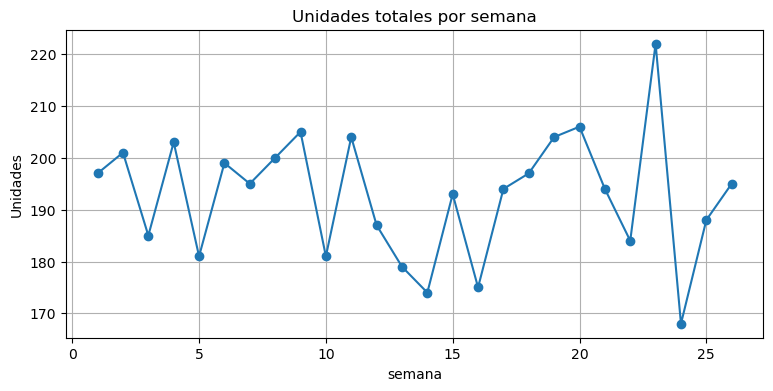

In [17]:
# FASE 4 — EXPLORACIÓN (Datlas)
top_faltante = (df.groupby("producto")["stockout_sem"]
                .mean().mul(100).round(1)
                .sort_values(ascending=False).head(10)).to_frame(name="% faltante")
display(top_faltante)

serie_total = df.groupby("semana")["unidades_vendidas"].sum()
display(serie_total.tail().to_frame(name="unidades"))

import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True
serie_total.plot(marker="o")
plt.title("Unidades totales por semana")
plt.ylabel("Unidades")
plt.show()


In [18]:
# FASE 5 — MODELADO (Datlas) — tendencia lineal
import numpy as np

serie = serie_total.reset_index()
X = serie["semana"].to_numpy().reshape(-1, 1)
y = serie["unidades_vendidas"].to_numpy()
Xd = np.hstack([X, np.ones_like(X)])

# Cálculo de la pendiente (a) y el intercepto (b) por mínimos cuadrados
a, b = np.linalg.pinv(Xd.T @ Xd) @ (Xd.T @ y)

next_week = int(serie["semana"].max() + 1)
y_next = a * next_week + b

print(f"Pronóstico total para semana {next_week}: {y_next:.1f}")


Pronóstico total para semana 27: 191.4


In [19]:
# FASE 6 — EVALUACIÓN Y COMUNICACIÓN (Datlas)
kpi_baseline = df["stockout_sem"].mean() * 100

resumen = f"""
KPI base: {kpi_baseline:.1f}% de semanas con faltante.
Pronóstico próximo período (unidades totales): {y_next:.1f}.
Decisión propuesta: aplicar reglas de reorden a productos críticos (ver Fase 7) para reducir ≥20% faltantes.
Riesgos: variabilidad estacional y lead time.
Siguiente paso: monitoreo semanal y recalibración de umbrales.
"""

print(resumen.strip())


KPI base: 0.6% de semanas con faltante.
Pronóstico próximo período (unidades totales): 191.4.
Decisión propuesta: aplicar reglas de reorden a productos críticos (ver Fase 7) para reducir ≥20% faltantes.
Riesgos: variabilidad estacional y lead time.
Siguiente paso: monitoreo semanal y recalibración de umbrales.


In [22]:
# FASE 7 — IMPLEMENTACIÓN (Datlas) — reglas prescriptivas
# pronóstico por producto (media 3 semanas) -> cobertura

agg = df.groupby(["producto", "semana"], as_index=False)["unidades_vendidas"].sum()

hist3 = agg.sort_values(["producto", "semana"]).groupby("producto", group_keys=False).tail(3)

prom3 = (hist3.groupby("producto", as_index=False)["unidades_vendidas"]
         .mean().rename(columns={"unidades_vendidas": "forecast_next"}))

base = df[df["semana"] == df["semana"].max()].copy().merge(prom3, on="producto", how="left")

base["forecast_next"] = base["forecast_next"].fillna(base["unidades_vendidas"]).clip(lower=1)

base["cobertura_sem"] = (base["stock_fin_sem"] / base["forecast_next"]).replace([np.inf, -np.inf], np.nan).fillna(999.0)

UMBRAL_COB = 1.2
UMBRAL_LT = 5

base["alerta_reorden"] = ((base["cobertura_sem"] < UMBRAL_COB) & (base["lead_time_dias"] >= UMBRAL_LT)).astype(int)

reorden = base.loc[base["alerta_reorden"] == 1, ["producto", "stock_fin_sem", "forecast_next", "cobertura_sem", "lead_time_dias"]]

reorden.to_csv("Reorden_semana_actual.csv", index=False)

print("Generado: Reorden_semana_actual.csv")
display(reorden.head(10))


Generado: Reorden_semana_actual.csv


,producto,stock_fin_sem,forecast_next,cobertura_sem,lead_time_dias
1,Ibuprofeno_400mg,32,29.0,1.103448,5


In [25]:
# === FASE 8 · Tablero ejecutivo (gráficos) ===

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ----------------- (A) Reconstrucción mínima si no existe 'base' -----------------

if "base" not in globals():
    # Última semana y pronóstico simple por producto (media 3 semanas) para cobertura
    agg = df.groupby(["producto", "semana"], as_index=False)["unidades_vendidas"].sum()
    
    hist3 = agg.sort_values(["producto", "semana"]).groupby("producto", group_keys=False).tail(3)
    
    prom3 = (hist3.groupby("producto", as_index=False)["unidades_vendidas"]
             .mean().rename(columns={"unidades_vendidas": "forecast_next"}))
    
    base = df[df["semana"] == df["semana"].max()].copy().merge(prom3, on="producto", how="left")
    
    base["forecast_next"] = base["forecast_next"].fillna(base["unidades_vendidas"]).clip(lower=1)
    
    base["cobertura_sem"] = (base["stock_fin_sem"] / base["forecast_next"]).replace([np.inf, -np.inf], np.nan).fillna(999.0)
    
    if "tasa_venta" not in base.columns:
        base["tasa_venta"] = (base["unidades_vendidas"] / base["stock_inicio_sem"]).clip(0, 1).fillna(0)

# Umbrales actuales (ajústalos)
COB = 1.2  # cobertura mínima aceptable en semanas
LT = 5     # lead time mínimo para disparar (días)


In [26]:
# ----------------- (B) KPIs ejecutivos -----------------

# # 1) KPI de faltante semanal (total) y baseline
kpi_sem = df.groupby("semana")["stockout_sem"].mean() * 100
kpi_baseline = kpi_sem.mean()

# # 2) Alertas actuales
alertas_mask = (base["cobertura_sem"] < COB) & (base["lead_time_dias"] >= LT)
n_alertas = int(alertas_mask.sum())
productos_alertas = base.loc[alertas_mask, "producto"].tolist()

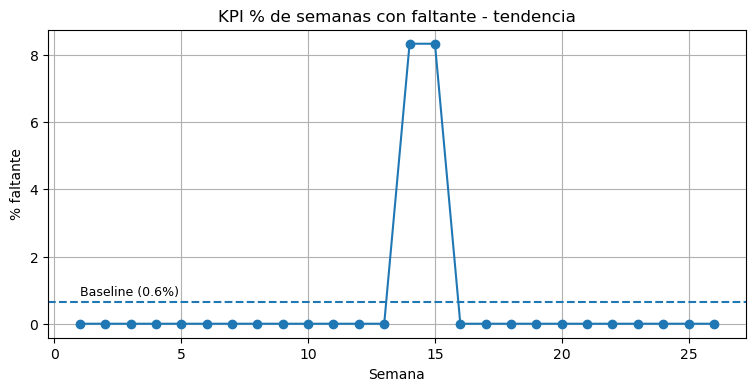

In [27]:
# ----------------- (C) Gráfico 1: KPI faltante (tendencia) -----------------

plt.figure()
kpi_sem.plot(marker="o")
plt.axhline(kpi_baseline, linestyle="--")
plt.title("KPI % de semanas con faltante - tendencia")
plt.ylabel("% faltante")
plt.xlabel("Semana")

# Corrección de la cadena de texto cortada
plt.text(kpi_sem.index.min(), kpi_baseline + 0.2, f"Baseline ({kpi_baseline:.1f}%)", fontsize=9)

plt.show()

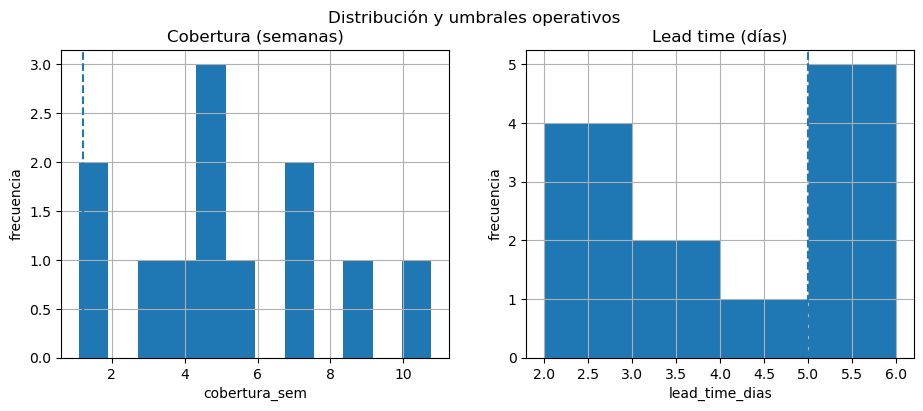

In [28]:
# ----------------- - (D) Gráfico 2: Distribuciones con umbrales -----------------

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# Primer subplot: Histograma de Cobertura
ax[0].hist(base["cobertura_sem"], bins=12)
ax[0].axvline(COB, linestyle="--")
ax[0].set_title("Cobertura (semanas)")
ax[0].set_xlabel("cobertura_sem")
ax[0].set_ylabel("frecuencia")

# Segundo subplot: Histograma de Lead Time
bins_lt = range(int(base["lead_time_dias"].min()), int(base["lead_time_dias"].max()) + 1)
ax[1].hist(base["lead_time_dias"], bins=bins_lt)
ax[1].axvline(LT, linestyle="--")
ax[1].set_title("Lead time (días)")
ax[1].set_xlabel("lead_time_dias")
ax[1].set_ylabel("frecuencia")

plt.suptitle("Distribución y umbrales operativos")
plt.show()

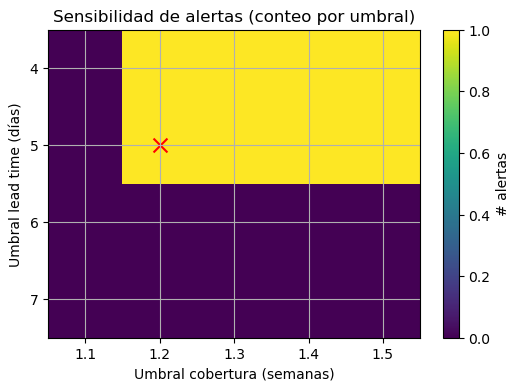

In [29]:
# ----------------- (E) Gráfico 3: Sensibilidad (heatmap) -----------------

cobs = np.array([1.1, 1.2, 1.3, 1.4, 1.5])
lts = np.array([4, 5, 6, 7])

M = np.zeros((len(lts), len(cobs)), dtype=int)

# Corrección de bucles e indexación matricial
for i, lt_ in enumerate(lts):
    for j, cb in enumerate(cobs):
        M[i, j] = int(((base["cobertura_sem"] < cb) & (base["lead_time_dias"] >= lt_)).sum())

plt.figure(figsize=(6, 4))
plt.imshow(M, aspect="auto")
plt.colorbar(label="# alertas")

plt.xticks(range(len(cobs)), cobs)
plt.yticks(range(len(lts)), lts)

plt.xlabel("Umbral cobertura (semanas)")
plt.ylabel("Umbral lead time (días)")
plt.title("Sensibilidad de alertas (conteo por umbral)")

# Marcar el punto actual
j = np.where(cobs == COB)[0][0] if COB in cobs else None
i = np.where(lts == LT)[0][0] if LT in lts else None

if i is not None and j is not None:
    plt.scatter([j], [i], s=100, marker="x", color="red")  # Se añade color para que resalte la 'X'

plt.show()

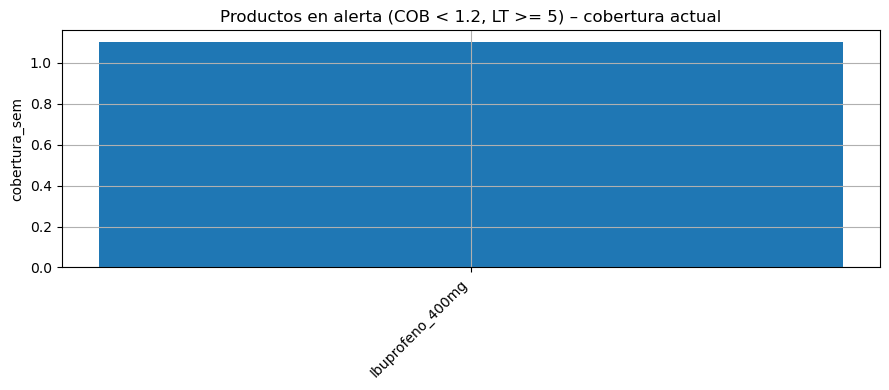

In [30]:
# ----------------- (F) Gráfico 4: Productos en alerta (si hay) -----------------

if n_alertas > 0:
    # Selección y ordenamiento de los productos en alerta
    tabla_alerta = (base.loc[alertas_mask, ["producto", "cobertura_sem", "lead_time_dias"]]
                    .sort_values(["cobertura_sem", "lead_time_dias"]))
    
    plt.figure(figsize=(9, 4))
    plt.bar(tabla_alerta["producto"], tabla_alerta["cobertura_sem"])
    plt.xticks(rotation=45, ha="right")
    
    plt.title(f"Productos en alerta (COB < {COB}, LT >= {LT}) – cobertura actual")
    plt.ylabel("cobertura_sem")
    
    plt.tight_layout()
    plt.show()

else:
    print("No hay productos en alerta con los umbrales actuales.")

In [31]:
# ------------------ (G) Resumen ejecutivo (texto) ----------------

obj_meta = 20  # meta de reducción %

resumen = f"""
RESUMEN EJECUTIVO — Fase 8 (Datlas)

• KPI promedio histórico de faltantes: {kpi_baseline:.1f}%.

• Alertas actuales (COB < {COB}, LT >= {LT}): {n_alertas} producto(s) -> {', '.join(productos_alertas) if productos_alertas else '—'}.

• Sensibilidad: con COB=1.4 y LT=5 se obtendrían {int(((base['cobertura_sem'] < 1.4) & (base['lead_time_dias'] >= 5)).sum())} alertas;
  con COB=1.2 y LT=6 serían {int(((base['cobertura_sem'] < 1.2) & (base['lead_time_dias'] >= 6)).sum())}.

• Recomendación: calibrar umbrales para mantener 15–35% de SKUs en alerta operable;
  monitorear semanalmente precisión de alertas y tendencia del KPI para alcanzar >= {obj_meta}% de reducción.
"""

print(resumen.strip())

RESUMEN EJECUTIVO — Fase 8 (Datlas)

• KPI promedio histórico de faltantes: 0.6%.

• Alertas actuales (COB < 1.2, LT >= 5): 1 producto(s) -> Ibuprofeno_400mg.

• Sensibilidad: con COB=1.4 y LT=5 se obtendrían 1 alertas;
  con COB=1.2 y LT=6 serían 0.

• Recomendación: calibrar umbrales para mantener 15–35% de SKUs en alerta operable;
  monitorear semanalmente precisión de alertas y tendencia del KPI para alcanzar >= 20% de reducción.
